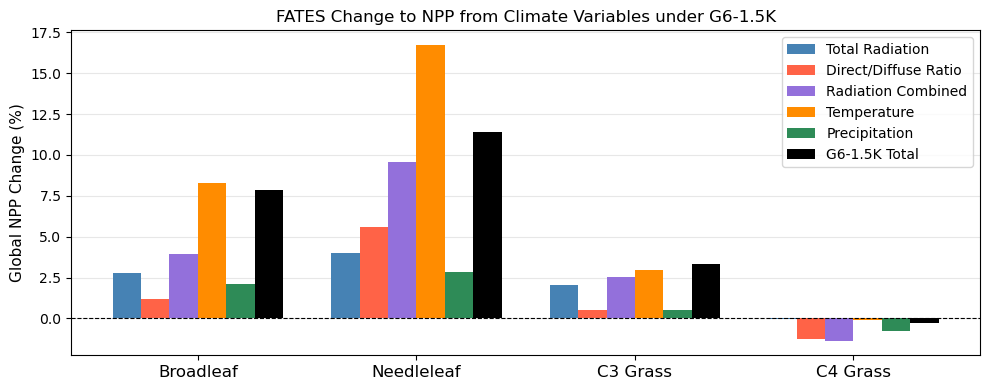

In [2]:
import pyreadr
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm
import xarray as xr
import numpy as np
import pandas as pd
from scipy.special import expit 
import os

case1_dir = '/glade/derecho/scratch/brendanc/fates_output/radiation/FATES_case1'
case2_dir = '/glade/derecho/scratch/brendanc/fates_output/radiation/FATES_case2'
ssp_dir = '/glade/derecho/scratch/brendanc/fates_output/radiation/FATES_ssp245'
temp_dir = '/glade/derecho/scratch/brendanc/fates_output/radiation/FATES_temperature'
precip_dir = '/glade/derecho/scratch/brendanc/fates_output/radiation/FATES_precip'
total_dir = '/glade/derecho/scratch/brendanc/make_pft'

case1 = xr.open_dataset(case1_dir + "/fates_G6_rad_case1_ctsm5.3.085.2035-2069.clm2.h1a.NPP.nc")
case1 = case1["FATES_NPP_latlon"]
case2 = xr.open_dataset(case2_dir + "/fates_G6_rad_case2_ctsm5.3.085.2035-2069.clm2.h1a.NPP.nc")
case2 = case2["FATES_NPP_latlon"] 
ssp = xr.open_dataset(ssp_dir + "/fates_SSP245_ctsm5.3.085_tranCO2_2015-2069.clm2.h1a.NPP.nc")
ssp = ssp["FATES_NPP_latlon"] 
temp = xr.open_dataset(temp_dir + "/fates_G6_temperature_ctsm5.3.085.2035-2069.clm2.h1a.NPP_latlon.nc")
temp = temp["FATES_NPP_latlon"]
precip = xr.open_dataset(precip_dir + "/fates_G6_precip_ctsm5.3.085.2035-2069.clm2.h1a.NPP_latlon.nc")
precip = precip["FATES_NPP_latlon"]
total = xr.open_dataset(total_dir + "/fates_G6_1.5K_full_ctsm5.3.085.2035-2069.clm2.h1a.NPPlatlon.nc")
total = total["FATES_NPP_latlon"]

case1 = case1.sel(time=slice('2050-01-01', '2069-12-31'))
case2 = case2.sel(time=slice('2050-01-01', '2069-12-31'))
ssp = ssp.sel(time=slice('2050-01-01', '2069-12-31'))
temp = temp.sel(time=slice('2050-01-01', '2069-12-31'))
precip = precip.sel(time=slice('2050-01-01', '2069-12-31'))
total = total.sel(time=slice('2050-01-01', '2069-12-31'))

case1 = case1.mean(dim=("time","fates_levscls"), skipna=True)
case2 = case2.mean(dim=("time","fates_levscls"), skipna=True)
ssp = ssp.mean(dim=("time","fates_levscls"), skipna=True)
temp = temp.mean(dim=("time","fates_levscls"), skipna=True)
precip = precip.mean(dim=("time","fates_levscls"), skipna=True)
total = total.mean(dim=("time","fates_levscls"), skipna=True)

case1 = case1 * 3.15576e10
case2 = case2 * 3.15576e10
ssp = ssp * 3.15576e10
temp = temp * 3.15576e10
precip = precip * 3.15576e10
total = total * 3.15576e10

import numpy as np

def global_mean(da):
    weights = np.cos(np.deg2rad(da.lat))
    weights.name = "weights"
    weighted = da.weighted(weights)
    return weighted.mean(dim=("lat", "lon"), skipna=True)

ssp_mean    = global_mean(ssp)
case1_mean  = global_mean(case1)
case2_mean  = global_mean(case2)
temp_mean   = global_mean(temp)
precip_mean = global_mean(precip)
total_mean  = global_mean(total)

tot_rad_dif  = (case1_mean - ssp_mean)
dirdif_dif   = (case2_mean - case1_mean)
temp_dif     = (temp_mean - ssp_mean)
precip_dif   = (precip_mean - ssp_mean)
total_dif    = (total_mean - ssp_mean)

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

broad_pfts = [1, 4, 5, 6]
ever_pfts  = [2, 3]
c3_pfts    = [13]
c4_pfts    = [14]   

lat_weights = np.cos(np.deg2rad(ssp.lat))
lat_weights = lat_weights / lat_weights.sum()

def area_weighted_mean(da):
    return float(da.weighted(lat_weights).mean(('lat', 'lon'), skipna=True))

def select_pfts(da, pft_list):
    return da.sel(fates_levpft=pft_list).sum('fates_levpft')

def pct_diff(a, b):
    return (a - b) / b * 100

def compute_group(pft_list):
    ssp_g    = select_pfts(ssp, pft_list)
    case1_g  = select_pfts(case1, pft_list)
    case2_g  = select_pfts(case2, pft_list)
    temp_g   = select_pfts(temp, pft_list)
    precip_g = select_pfts(precip, pft_list)
    total_g  = select_pfts(total, pft_list)

    ssp_m    = area_weighted_mean(ssp_g)
    case1_m  = area_weighted_mean(case1_g)
    case2_m  = area_weighted_mean(case2_g)
    temp_m   = area_weighted_mean(temp_g)
    precip_m = area_weighted_mean(precip_g)
    total_m  = area_weighted_mean(total_g)

    tot_rad  = pct_diff(case1_m, ssp_m)
    dirdif   = pct_diff(case2_m, case1_m)
    temp_d   = pct_diff(temp_m, ssp_m)
    precip_d = pct_diff(precip_m, ssp_m)
    total_d  = pct_diff(total_m, ssp_m)

    return tot_rad, dirdif, temp_d, precip_d, total_d

groups = {
    'Broadleaf':  compute_group(broad_pfts),
    'Needleleaf': compute_group(ever_pfts),
    'C3 Grass':   compute_group(c3_pfts),
    'C4 Grass':   compute_group(c4_pfts),
}

labels      = list(groups.keys())
tot_vals    = [groups[k][0] for k in labels]
dif_vals    = [groups[k][1] for k in labels]
temp_vals   = [groups[k][2] for k in labels]
precip_vals = [groups[k][3] for k in labels]
total_vals  = [groups[k][4] for k in labels]
com_vals    = [t + d for t, d in zip(tot_vals, dif_vals)]

x     = np.arange(len(labels))
width = 0.13

fig, ax = plt.subplots(figsize=(10, 4))
ax.grid(axis='y', alpha=0.3, zorder=0)

bars1 = ax.bar(x - 2.5*width, tot_vals,    width, label='Total Radiation',      color='steelblue',    zorder=2)
bars2 = ax.bar(x - 1.5*width, dif_vals,    width, label='Direct/Diffuse Ratio', color='tomato',       zorder=2)
bars3 = ax.bar(x - 0.5*width, com_vals,    width, label='Radiation Combined',   color='mediumpurple', zorder=2)
bars4 = ax.bar(x + 0.5*width, temp_vals,   width, label='Temperature',          color='darkorange',   zorder=2)
bars5 = ax.bar(x + 1.5*width, precip_vals, width, label='Precipitation',        color='seagreen',     zorder=2)
bars6 = ax.bar(x + 2.5*width, total_vals,  width, label='G6-1.5K Total',        color='black',        zorder=2)

ax.axhline(0, color='k', linewidth=0.8, linestyle='--', zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel('Global NPP Change (%)', fontsize=11)
ax.set_title('FATES Change to NPP from Climate Variables under G6-1.5K', fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
savedir = "/glade/derecho/scratch/brendanc/fates_output/radiation"
plt.savefig(f"{savedir}/FATES_bars_total.png", dpi=600, bbox_inches="tight")

In [3]:
print("G6-1.5K Total NPP change (%):")
for label, val in zip(labels, total_vals):
    print(f"  {label:<12}: {val:.2f}%")

G6-1.5K Total NPP change (%):
  Broadleaf   : 7.84%
  Needleleaf  : 11.41%
  C3 Grass    : 3.34%
  C4 Grass    : -0.28%
